<a href="https://colab.research.google.com/github/y-adulyasak/SCOA_PhD/blob/main/S10_P2P/Newsvendor_p2p_pyomo_S1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The newsvendor as a sampling-based LP
**Professor: Yossiri Adulyasak**

**PhD Seminar, Session 10 (From Predictive to Prescriptive Analytics).**Pyomo** with the open-source **HiGHS** solver.

Every approach in this notebook solves the **same** sampling-based LP. The only things that change are
the demand scenarios $d_s$ handed to it and their weights $w_s$:

| approach | uses temperature $x$? | uses the spread of demand? | scenarios $d_s$ | weights $w_s$ |
|---|---|---|---|---|
| **Deterministic** | no | no | 1: the historical mean | 1 |
| **Predict-then-optimize (PtO)** | yes | no | 1: a forecast $\hat d(x)$ | 1 |
| **SAA** | no | yes | all $N$ past days | $1/N$ |
| **P2P with kNN** | yes | yes | the $k$ past days with the closest temperature | $1/k$ |
| **P2P with a decision tree** | yes | yes | the past days in the same leaf as $x$ | $1/\text{leaf size}$ |
| **P2P with Nadaraya–Watson** | yes | yes | all $N$ past days | kernel weights that fade with the temperature gap |

The kiosk data and the 150 test days are the ones shown on the slides.

In [1]:
!pip install -q "pyomo>=6.9" highspy
import time, numpy as np, matplotlib.pyplot as plt
import pyomo, pyomo.environ as pyo
from scipy.stats import norm
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

SOLVER = pyo.SolverFactory("highs")        # HiGHS: open-source LP/MIP solver, installed by highspy
assert SOLVER.available(), "HiGHS not found: run  !pip install -U pyomo highspy  and restart the runtime"
print("Pyomo", pyomo.__version__, "with HiGHS: ready")

Pyomo 6.10.1 with HiGHS: ready


---
# Part 1: Problem and data

A kiosk orders $z$ units of crossant each morning, before demand $D$ is known. Leftovers
cost $h = \$1$ per unit, profit margin $p = \$3$ per unit. The kiosk sees tomorrow's temperature $x$ before
ordering. We have 20 days of history $(x_i, d_i)$.

To properly evaluate each approach we need days it has never seen (test set): 150 new days are generated using demand
$= -14 + 2.6\,x + \varepsilon$ with $\varepsilon \sim N(0, 5^2)$, rounded.

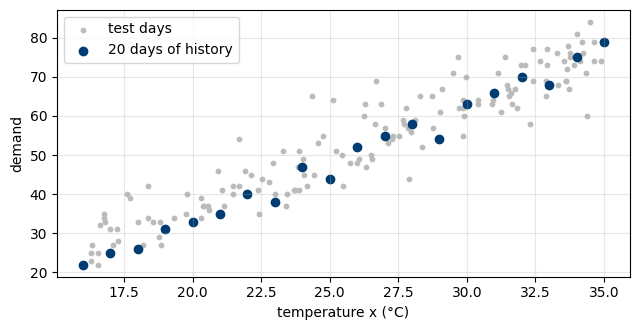

In [2]:
H, P = 1.0, 3.0                          # leftover cost h, shortage cost p
TEMP = np.array([16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35.])
DEM  = np.array([22,25,26,31,33,35,40,38,47,44,52,55,58,54,63,66,70,68,75,79.])
N = len(DEM)

def nv_cost(z, d):
    # realized cost of ordering z when demand turns out to be d
    return H*np.maximum(z - d, 0) + P*np.maximum(d - z, 0)

rng = np.random.default_rng(0)
sd = 5
T_TEST = rng.uniform(16, 35, 150)
D_TEST = np.clip(np.round(-14 + 2.6*T_TEST + rng.normal(0, sd, 150)), 1, None)

plt.figure(figsize=(6.5, 3.4))
plt.scatter(T_TEST, D_TEST, s=10, color="#BBBBBB", label="test days")
plt.scatter(TEMP, DEM, color="#003C71", label="20 days of history")
plt.xlabel("temperature x (°C)"); plt.ylabel("demand"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# Part 2: Sampling-based LP

Given scenarios $d_1,\dots,d_S$ with weights $w_1,\dots,w_S$ (non-negative, summing to 1):

$$
\begin{aligned}
\min_{z,\;o,\;u}\quad & \sum_{s=1}^{S} w_s\,\bigl(h\,o_s + p\,u_s\bigr)\\
\text{s.t.}\quad & o_s \ge z - d_s\qquad s = 1,\dots,S\\ & u_s \ge d_s - z, \qquad s = 1,\dots,S\\
& z \ge 0,\quad o_s \ge 0,\quad u_s \ge 0 .
\end{aligned}
$$

* $z$ is the **first-stage** decision: order quantity.
* $o_s$ (leftovers) and $u_s$ (shortage) are **recourse** variables: one copy per scenario.
* At the optimum $o_s = (z-d_s)^+$ and $u_s = (d_s-z)^+$, so the objective is exactly
  $\sum_s w_s\, c(z; d_s)$, the weighted average cost.

This is a two-stage stochastic program.

**Note.** We add a tiny cost of $10^{-6}$ per unit ordered so the solver returns the smallest optimal order when several quantities in an interval yield the same cost. It does not change the expected cost by more than $10^{-4}$.

In [3]:
TIE = 1e-6        # tiny per-unit cost: among equally good orders, return the smallest

def newsvendor_lp(scenarios, weights, h=H, p=P):
    # Build the sampling-based newsvendor LP. Scenarios with zero weight are left out.
    keep = np.asarray(weights, float) > 0
    d = dict(enumerate(np.asarray(scenarios, float)[keep], start=1))
    w = dict(enumerate(np.asarray(weights, float)[keep], start=1))
    m = pyo.ConcreteModel("newsvendor")
    m.S = pyo.Set(initialize=list(d))                         # scenarios s = 1..S
    m.z = pyo.Var(domain=pyo.NonNegativeReals)                # stage 1: the order, one value for all s
    m.o = pyo.Var(m.S, domain=pyo.NonNegativeReals)           # stage 2: leftovers in scenario s
    m.u = pyo.Var(m.S, domain=pyo.NonNegativeReals)           # stage 2: shortage in scenario s
    m.leftover = pyo.Constraint(m.S, rule=lambda m, s: m.o[s] >= m.z - d[s])
    m.shortage = pyo.Constraint(m.S, rule=lambda m, s: m.u[s] >= d[s] - m.z)
    m.expected_cost = pyo.Expression(expr=sum(w[s]*(h*m.o[s] + p*m.u[s]) for s in m.S))
    m.objective = pyo.Objective(expr=m.expected_cost + TIE*m.z, sense=pyo.minimize)
    return m

def solve(m):
    result = SOLVER.solve(m)
    assert result.solver.termination_condition == pyo.TerminationCondition.optimal
    return pyo.value(m.z)

def order(scenarios, weights, h=H, p=P):
    # Optimal order for given scenarios and weights: build the LP and solve it.
    return solve(newsvendor_lp(scenarios, weights, h, p))

# A three-scenario example, to see the model Pyomo builds
m = newsvendor_lp([22, 33, 26], [0.5, 0.25, 0.25])
print("minimize  ", m.expected_cost.expr)
print("subject to")
for s in m.S:
    print(f"   {str(m.leftover[s].expr):18s}   {m.shortage[s].expr}")
z = solve(m)
print(f"\noptimal order z = {z:.0f},  expected cost = {pyo.value(m.expected_cost):.2f}")

minimize   0.5*(o[1] + 3.0*u[1]) + 0.25*(o[2] + 3.0*u[2]) + 0.25*(o[3] + 3.0*u[3])
subject to
   z - 22.0  <=  o[1]   22.0 - z  <=  u[1]
   z - 33.0  <=  o[2]   33.0 - z  <=  u[2]
   z - 26.0  <=  o[3]   26.0 - z  <=  u[3]

optimal order z = 26,  expected cost = 7.25


With weights $(0.5, 0.25, 0.25)$ on demands $(22, 33, 26)$ the LP orders 26. Ordering one more unit
saves \$3 only in the scenario with demand 33 (weight 0.25, so \$0.75 on average) and loses \$1 in the
other two (weight 0.75, so \$0.75).

---
# Part 3: Deterministic: one scenario using the historical mean

Hand the LP a single scenario, the average of the 20 past demands, with weight 1.

In [4]:
d_bar = DEM.mean()
z_det = order([d_bar], [1.0])
print(f"historical mean demand = {d_bar:.2f}   ->   deterministic order = {z_det:.2f}")

print("\nThe deterministic order ignores the costs:")
for p_ in [3, 9, 19]:
    print(f"   shortage cost p = {p_:>2}:  order {order([d_bar], [1.0], p=p_):.2f}")

historical mean demand = 49.05   ->   deterministic order = 49.05

The deterministic order ignores the costs:
   shortage cost p =  3:  order 49.05
   shortage cost p =  9:  order 49.05
   shortage cost p = 19:  order 49.05


With one scenario there is nothing to hedge: the LP orders exactly the scenario, whatever $h$ and $p$
are. The cost asymmetry does not change the decision.

---
# Part 4: SAA: all 20 days as scenarios, weight 1/20 each

In [5]:
W_SAA = np.full(N, 1/N)
m = newsvendor_lp(DEM, W_SAA)
m.pprint()
z_saa = solve(m)
best = pyo.value(m.expected_cost)
print(f"SAA: {N} scenarios, weight 1/{N} each  ->  order {z_saa:.0f}   (in-sample cost {best:.2f} per day)")

m.objective.deactivate()
m.stay_optimal = pyo.Constraint(expr=m.expected_cost <= best + 1e-6)
m.push_down = pyo.Objective(expr=m.z, sense=pyo.minimize); z_lo = solve(m)
m.push_down.deactivate()
m.push_up = pyo.Objective(expr=m.z, sense=pyo.maximize);   z_hi = solve(m)
print(f"every order between {z_lo:.0f} and {z_hi:.0f} is optimal")
print(f"check against the formula: the 0.75-quantile of the 20 demands is {np.sort(DEM)[14]:.0f}"
      f" (15 of 20 days have demand at or below it)")

print("\nUnlike the deterministic model, SAA responds to the costs:")
for p_ in [3, 9, 19]:
    print(f"   shortage cost p = {p_:>2} (critical ratio {p_/(p_+H):.2f}):  SAA order {order(DEM, W_SAA, p=p_):.0f}")

1 Set Declarations
    S : Size=1, Index=None, Ordered=Insertion
        Key  : Dimen : Domain : Size : Members
        None :     1 :    Any :   20 : {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20}

3 Var Declarations
    o : Size=20, Index=S
        Key : Lower : Value : Upper : Fixed : Stale : Domain
          1 :     0 :  None :  None : False :  True : NonNegativeReals
          2 :     0 :  None :  None : False :  True : NonNegativeReals
          3 :     0 :  None :  None : False :  True : NonNegativeReals
          4 :     0 :  None :  None : False :  True : NonNegativeReals
          5 :     0 :  None :  None : False :  True : NonNegativeReals
          6 :     0 :  None :  None : False :  True : NonNegativeReals
          7 :     0 :  None :  None : False :  True : NonNegativeReals
          8 :     0 :  None :  None : False :  True : NonNegativeReals
          9 :     0 :  None :  None : False :  True : NonNegativeReals
         10 :     0 :  None :  N

**SAA uses the spread and the costs, but not the context.** It orders 63 every day, cold or hot.

---
# Part 5: Predict-then-Optimize (PtO): one scenario using a forecast $\hat d(x)$

First learn a forecast of demand from temperature, then solve the LP using that single estimated demand. Four ML models:

* **kNN mean**: the average demand of the $k = 5$ past days with the closest temperature;
* **tree mean**: a regression tree whose leaves hold at least 5 past days, predicting the leaf's average;
* **Nadaraya–Watson mean**: a weighted average of **all** past demands, with Gaussian kernel weights that fade with the temperature gap (bandwidth $b = 2$ °C);
* **linear regression** of demand on temperature.


**Note: Nadaraya–Watson** keeps **all** past days as scenarios, with weights

$$w_i(x) = \frac{K\bigl((x - x_i)/b\bigr)}{\sum_{j} K\bigl((x - x_j)/b\bigr)}, \qquad K(u) = e^{-u^2/2}.$$

There is no cut-off: a day 1 °C away counts almost as much as one at today's temperature, a day 6 °C away
almost nothing. The bandwidth $b$ plays the role of $k$.

kNN, the tree and Nadaraya–Watson are the same ML models P2P will use.

In [6]:
K = 5

def knn_weights(x, X=TEMP, k=K):
    # 1/k on the k past days with the closest temperature, 0 elsewhere
    w = np.zeros(len(X))
    w[np.argsort(np.abs(X - x), kind="stable")[:k]] = 1/k
    return w

tree = DecisionTreeRegressor(min_samples_leaf=K, random_state=0).fit(TEMP.reshape(-1, 1), DEM)
LEAF = tree.apply(TEMP.reshape(-1, 1))           # leaf of each past day

def tree_weights(x):
    # equal weight on the past days that fall in the same leaf as x
    w = (LEAF == tree.apply([[x]])[0]).astype(float)
    return w / w.sum()

BANDWIDTH = 2.0                                  # b, in °C: how fast the weight fades with the temperature gap

def nw_weights(x, X=TEMP, b=BANDWIDTH):
    # Nadaraya-Watson: every past day gets the Gaussian kernel weight K((x - x_i)/b), normalized to sum to 1
    kernel = np.exp(-0.5 * ((X - x) / b) ** 2)
    return kernel / kernel.sum()

linreg = LinearRegression().fit(TEMP.reshape(-1, 1), DEM)

FORECAST = {"kNN mean":          lambda x: knn_weights(x) @ DEM,
            "tree mean":         lambda x: tree_weights(x) @ DEM,
            "Nadaraya–Watson mean": lambda x: nw_weights(x) @ DEM,
            "linear regression": lambda x: linreg.predict([[x]])[0]}

print(f"{'forecaster':20s}{'18 °C: forecast':>16s}{'order':>8s}{'30 °C: forecast':>18s}{'order':>8s}")
for name, f in FORECAST.items():
    print(f"{name:20s}{f(18):>16.1f}{order([f(18)], [1.0]):>8.1f}{f(30):>18.1f}{order([f(30)], [1.0]):>8.1f}")

forecaster           18 °C: forecast   order   30 °C: forecast   order
kNN mean                        27.4    27.4              62.2    62.2
tree mean                       27.4    27.4              56.4    56.4
Nadaraya–Watson mean            28.4    28.4              61.9    61.9
linear regression               27.0    27.0              62.3    62.3


Each LP has a single scenario, so it orders exactly the forecast (same as the case of deterministic but the order quantity is different): PtO uses the context but does not consider the demand uncertainty around $\hat d(x)$.

---
# Part 6: P2P: same predictive models but keep the distribution

Instead of averaging the neighbours' demands into one forecast, utilize **all of them** in the LP through their weights. The weights are an estimate of the distribution of demand given $x$.


In [7]:
for x in [18.0, 30.0]:
    w = knn_weights(x); nz = np.flatnonzero(w)
    m = newsvendor_lp(DEM, w)
    print(f"x = {x:.0f} °C: kNN scenarios (temperature, demand) = "
          f"{[(int(TEMP[i]), int(DEM[i])) for i in nz]}, weight {w[nz[0]]:.1f} each")
    print(f"   the LP has {len(m.S)} scenarios and {len(m.leftover) + len(m.shortage)} constraints"
          f"  ->  P2P order {solve(m):.0f}   (PtO with the kNN mean: {knn_weights(x) @ DEM:.1f})\n")

print("Decision-tree leaves (each leaf is the scenario set for any x that falls in it):")
print(f"{'temperatures':>14s}   {'demands in the leaf':28s}{'PtO (leaf mean)':>16s}{'P2P (LP)':>10s}")
for leaf in np.unique(LEAF):
    members = LEAF == leaf
    x_in = TEMP[members][0]
    print(f"{TEMP[members].min():>7.0f} to {TEMP[members].max():<4.0f}   {str(DEM[members].astype(int).tolist()):28s}"
          f"{tree_weights(x_in) @ DEM:>16.1f}{order(DEM, tree_weights(x_in)):>10.0f}")

x = 18 °C: kNN scenarios (temperature, demand) = [(16, 22), (17, 25), (18, 26), (19, 31), (20, 33)], weight 0.2 each
   the LP has 5 scenarios and 10 constraints  ->  P2P order 31   (PtO with the kNN mean: 27.4)

x = 30 °C: kNN scenarios (temperature, demand) = [(28, 58), (29, 54), (30, 63), (31, 66), (32, 70)], weight 0.2 each
   the LP has 5 scenarios and 10 constraints  ->  P2P order 66   (PtO with the kNN mean: 62.2)

Decision-tree leaves (each leaf is the scenario set for any x that falls in it):
  temperatures   demands in the leaf          PtO (leaf mean)  P2P (LP)
     16 to 20     [22, 25, 26, 31, 33]                    27.4        31
     21 to 25     [35, 40, 38, 47, 44]                    40.8        44
     26 to 30     [52, 55, 58, 54, 63]                    56.4        58
     31 to 35     [66, 70, 68, 75, 79]                    71.6        75


At 18 °C both P2P versions use the same five days, 16–20 °C, and order 31 vs SAA's 63. With $p = 3h$, the LP orders the fourth-smallest of five demands.

**Nadaraya–Watson at 18 °C and 30 °C.** The *effective number of days*, $1/\sum_i w_i^2$, says how many
equally weighted days the weights are worth. Small $b$ leans on the closest day; large $b$ turns into SAA.

In [8]:
for x in [18.0, 30.0]:
    w = nw_weights(x)
    top = np.argsort(-w, kind="stable")[:7]
    print(f"x = {x:.0f} °C: largest weights (temperature, demand, weight) = "
          f"{[(int(TEMP[i]), int(DEM[i]), round(float(w[i]), 2)) for i in top]}")
    print(f"   all {N} days are scenarios, worth {1/np.sum(w**2):.1f} equally weighted days"
          f"  ->  P2P order {order(DEM, w):.0f}   (PtO with the NW mean: {w @ DEM:.1f})\n")

print("The bandwidth b plays the role of k:")
print(f"{'b (°C)':>8s}{'effective days at 18 °C':>25s}{'order at 18 °C':>16s}{'order at 30 °C':>16s}")
for b in [0.5, 1, 2, 4, 8, 100]:
    w18, w30 = nw_weights(18, b=b), nw_weights(30, b=b)
    print(f"{b:>8}{1/np.sum(w18**2):>25.1f}{order(DEM, w18):>16.0f}{order(DEM, w30):>16.0f}")

x = 18 °C: largest weights (temperature, demand, weight) = [(18, 26, 0.22), (17, 25, 0.2), (19, 31, 0.2), (16, 22, 0.13), (20, 33, 0.13), (21, 35, 0.07), (22, 40, 0.03)]
   all 20 days are scenarios, worth 5.9 equally weighted days  ->  P2P order 33   (PtO with the NW mean: 28.4)

x = 30 °C: largest weights (temperature, demand, weight) = [(30, 63, 0.2), (29, 54, 0.18), (31, 66, 0.18), (28, 58, 0.12), (32, 70, 0.12), (27, 55, 0.06), (33, 68, 0.06)]
   all 20 days are scenarios, worth 7.1 equally weighted days  ->  P2P order 66   (PtO with the NW mean: 61.9)

The bandwidth b plays the role of k:
  b (°C)  effective days at 18 °C  order at 18 °C  order at 30 °C
     0.5                      1.6              26              63
       1                      3.5              31              66
       2                      5.9              33              66
       4                      9.4              38              68
       8                     15.7              52              66
  

---
# Part 7: Out of sample: 150 test days

Each approach turns a temperature into an order; we then pay the realized cost on 150 days that are drawn separately.
The **coefficient of prescriptiveness** measures how much of the possible improvement over SAA:

$$P = 1 - \frac{\text{cost} - \text{cost of perfect foresight}}{\text{cost of SAA} - \text{cost of perfect foresight}}$$

Here perfect foresight orders exactly the demand and costs 0, so $P = 1 - \text{cost}/\text{cost of SAA}$.

In [9]:
APPROACHES = {   # name: (uses temperature?, uses the spread?, policy x -> order)
    "Deterministic: historical mean":   ("no",  "no",  lambda x: order([d_bar], [1.0])),
    "PtO: kNN mean":                    ("yes", "no",  lambda x: order([FORECAST["kNN mean"](x)], [1.0])),
    "PtO: tree mean":                   ("yes", "no",  lambda x: order([FORECAST["tree mean"](x)], [1.0])),
    "PtO: linear regression":           ("yes", "no",  lambda x: order([FORECAST["linear regression"](x)], [1.0])),
    "PtO: Nadaraya–Watson mean":        ("yes", "no",  lambda x: order([FORECAST["Nadaraya–Watson mean"](x)], [1.0])),
    "SAA: 20 days, 1/20 each":          ("no",  "yes", lambda x: order(DEM, W_SAA)),
    "P2P: kNN weights (k = 5)":         ("yes", "yes", lambda x: order(DEM, knn_weights(x))),
    "P2P: tree weights":                ("yes", "yes", lambda x: order(DEM, tree_weights(x))),
    "P2P: Nadaraya–Watson (b = 2 °C)":  ("yes", "yes", lambda x: order(DEM, nw_weights(x))),
}
t0 = time.time()
ORDERS = {name: np.array([pol(x) for x in T_TEST]) for name, (_, _, pol) in APPROACHES.items()}
COST = {name: nv_cost(z, D_TEST).mean() for name, z in ORDERS.items()}
print(f"{len(APPROACHES)*len(T_TEST):,} LPs solved ({len(APPROACHES)} approaches x {len(T_TEST)} days) in {time.time() - t0:.1f} s\n")

c_saa = COST["SAA: 20 days, 1/20 each"]
print(f"{'approach':33s}{'uses x':>7s}{'spread':>8s}{'distinct orders':>16s}{'cost/day':>10s}{'vs SAA':>8s}{'Pres.':>7s}")
print("-" * 89)
for name, (ux, us, _) in APPROACHES.items():
    c = COST[name]
    print(f"{name:33s}{ux:>7s}{us:>8s}{len(np.unique(ORDERS[name].round(6))):>16d}{c:>10.2f}"
          f"{100*(c/c_saa - 1):>+7.0f}%{1 - c/c_saa:>7.2f}")

# Ceilings: the true demand given x is N(-14 + 2.6x, 5^2)
# We use a closed-form formula for the expected cost when demand is normal and we know the true distribution exactly.
c_quant = (H + P) * sd * norm.pdf(norm.ppf(P/(P + H)))     # order its 0.75-quantile
c_mean  = (H + P) * sd * norm.pdf(0)                       # order its mean: the best point forecast
print("-" * 89)
print(f"{'know the true demand function, order its mean':33s}{'':19s}{c_mean:>10.2f}{100*(c_mean/c_saa - 1):>+7.0f}%{1 - c_mean/c_saa:>7.2f}"
      "   <- the best any point forecast can do")
print(f"{'know the true demand function, order its 0.75-quantile':33s}{'':10s}{c_quant:>10.2f}{100*(c_quant/c_saa - 1):>+7.0f}%{1 - c_quant/c_saa:>7.2f}"
      "   <- the ceiling")

1,350 LPs solved (9 approaches x 150 days) in 26.6 s

approach                          uses x  spread distinct orders  cost/day  vs SAA  Pres.
-----------------------------------------------------------------------------------------
Deterministic: historical mean        no      no               1     32.98    +61%  -0.61
PtO: kNN mean                        yes      no              16     11.92    -42%   0.42
PtO: tree mean                       yes      no               4     13.67    -33%   0.33
PtO: linear regression               yes      no             150     11.63    -43%   0.43
PtO: Nadaraya–Watson mean            yes      no             150     11.60    -43%   0.43
SAA: 20 days, 1/20 each               no     yes               1     20.49     +0%   0.00
P2P: kNN weights (k = 5)             yes     yes              15      8.23    -60%   0.60
P2P: tree weights                    yes     yes               4     10.23    -50%   0.50
P2P: Nadaraya–Watson (b = 2 °C)      yes     y

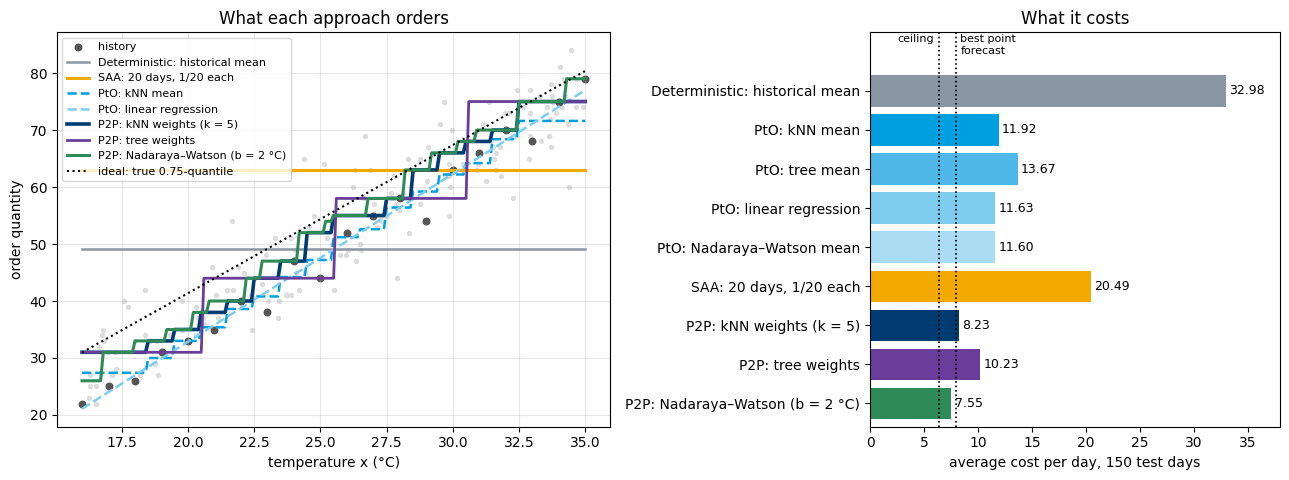

In [10]:
xs = np.arange(16, 35.01, 0.1)
style = {"Deterministic: historical mean": ("#8A97A3", "-",  1.8),
         "SAA: 20 days, 1/20 each":        ("#F2A900", "-",  2.2),
         "PtO: kNN mean":                  ("#009FDF", "--", 1.8),
         "PtO: linear regression":         ("#7FCDEE", "--", 1.8),
         "P2P: kNN weights (k = 5)":       ("#003C71", "-",  2.6),
         "P2P: tree weights":              ("#6A3D9A", "-",  2.0),
         "P2P: Nadaraya–Watson (b = 2 °C)": ("#2E8B57", "-",  2.2)}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.9), gridspec_kw={"width_ratios": [1.35, 1]})
ax[0].scatter(T_TEST, D_TEST, s=8, color="#DDDDDD", zorder=0)
ax[0].scatter(TEMP, DEM, s=22, color="#555555", zorder=1, label="history")
for name, (col, ls, lw) in style.items():
    ax[0].plot(xs, [APPROACHES[name][2](x) for x in xs], ls, color=col, lw=lw, label=name)
ax[0].plot(xs, -14 + 2.6*xs + 5*norm.ppf(0.75), ":", color="black", lw=1.5, label="ideal: true 0.75-quantile")
ax[0].set_xlabel("temperature x (°C)"); ax[0].set_ylabel("order quantity"); ax[0].grid(alpha=.3)
ax[0].legend(fontsize=8, loc="upper left"); ax[0].set_title("What each approach orders")

names = list(APPROACHES)
bar_color = {"Deterministic: historical mean": "#8A97A3", "PtO: kNN mean": "#009FDF", "PtO: tree mean": "#4FB8E8",
             "PtO: linear regression": "#7FCDEE", "PtO: Nadaraya–Watson mean": "#A9DCF2", "SAA: 20 days, 1/20 each": "#F2A900",
             "P2P: kNN weights (k = 5)": "#003C71", "P2P: tree weights": "#6A3D9A", "P2P: Nadaraya–Watson (b = 2 °C)": "#2E8B57"}
ax[1].barh(names[::-1], [COST[n] for n in names][::-1], color=[bar_color[n] for n in names[::-1]])
for v, lab, ha, dx in [(c_mean, "best point\nforecast", "left", 0.4), (c_quant, "ceiling", "right", -0.4)]:
    ax[1].axvline(v, color="black", ls=":", lw=1.2); ax[1].text(v + dx, len(names) + 0.45, lab, fontsize=8, ha=ha, va="top")
for i, n in enumerate(names[::-1]):
    ax[1].text(COST[n] + 0.3, i, f"{COST[n]:.2f}", va="center", fontsize=9)
ax[1].set_xlabel("average cost per day, 150 test days"); ax[1].set_xlim(0, 38); ax[1].set_ylim(-0.6, len(names) + 0.5); ax[1].set_title("What it costs")
plt.tight_layout(); plt.show()

### Reading the results

* **Deterministic is the worst, worse than SAA** (+63%). It orders 49 every day and ignores that a
  shortage costs three times a leftover.
* **Every PtO beats SAA.** Context matters: an order that follows the temperature beats a constant one,
  even when it is just a forecast.
* **Every P2P beats every PtO.** The same five neighbours
  cost 12.24 per day as a mean and 8.09 as a distribution. The same tree leaves cost 13.99 and 10.15.
  Using P2P scenarios reduces 27 to 34% of the cost.
* **P2P with 20 days is close to the best point forecast with infinite data.** P2P with kNN reaches 8.09, and its ceiling is 6.36.
* **The tree is coarser than kNN here.** It has 4 leaves, so 4 possible orders, against 16 neighbour sets for kNN. With one covariate and 20 points, a local method that moves with $x$ (i.e., kNN) is generally better while the trees could work well with many covariates.
* **Nadaraya–Watson is the best P2P here** (7.55 per day, P = 0.63). It uses all 20 days, with weights that fade with the temperature gap instead of an all-or-nothing cut-off.


---
# Part 8: Exercises

1. **Heteroscedastic demand.** Make the noise grow with temperature, e.g. sd $= 2 + 0.4\,(x - 16)$,
   in `kiosk` and in the test days. How do PtO and P2P with kNN perform?
2. **Constrained model.** Add a constraint `m.cap = pyo.Constraint(expr=m.z <= 60)` (shelf space) or a second product sharing a budget. The quantile formula no longer applies but the LP-based approach above can be easily modified.

